# 011. 새 데이터 승차 변화 시각화

2024-10-17과 2025-11-06을 비교하며, 공급구조가 유지된 126개 250m 격자만 분석한다.

In [1]:
from pathlib import Path
import warnings
import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.colors import TwoSlopeNorm
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, Image
warnings.filterwarnings('ignore')

PROJECT = Path.cwd().parent if Path.cwd().name == 'analysis' else Path.cwd()
ROOT = PROJECT.parents[1]
PROCESSED = PROJECT / 'data' / 'processed'
FIGURES = PROJECT / 'outputs' / 'figures_011'
FIGURES.mkdir(parents=True, exist_ok=True)
STABLE_PATH = PROCESSED / '16_새데이터_공급구조유지_250m격자.csv'
MODEL_PATH = PROCESSED / '18_새데이터_회귀분석_격자통합데이터.csv'
GRID_PATH = next((ROOT / 'Analisis2' / '빈격자(250m)').glob('*.shp'))
ADMIN_PATH = ROOT / 'api_cache_gtx_a_routes' / 'HangJeongDong_ver20260701.geojson'
CARD_DIR = ROOT / 'gtx_a_seoul_bus_outputs' / 'transport_card'
RAW24 = CARD_DIR / 'gtx_a_transport_card_20241017_raw_with_coords_api_filled.csv'
RAW25 = CARD_DIR / 'gtx_a_transport_card_20251106_raw_with_coords.csv'

font_path = Path(r'C:\Windows\Fonts\malgun.ttf')
if font_path.exists():
    fm.fontManager.addfont(str(font_path))
    plt.rcParams['font.family'] = fm.FontProperties(fname=str(font_path)).get_name()
plt.rcParams['axes.unicode_minus'] = False

stable = pd.read_csv(STABLE_PATH, encoding='utf-8-sig')
model = pd.read_csv(MODEL_PATH, encoding='utf-8-sig')
stable['셀 ID'] = pd.to_numeric(stable['셀 ID'], errors='coerce').astype('Int64')
model['셀 ID'] = pd.to_numeric(model['셀 ID'], errors='coerce').astype('Int64')
model['변화율(%)'] = np.where(model['board_2024_all'] > 0, model['change_all'] / model['board_2024_all'] * 100, np.nan)
assert len(stable) == 126 and len(model) == 126

admin = gpd.read_file(ADMIN_PATH)
grid_crs = gpd.read_file(GRID_PATH, rows=1).crs
admin = admin.to_crs(grid_crs)
admin['sgg_code'] = admin['sgg'].astype(str).str.extract(r'([0-9]+)')[0].str.zfill(5)
city = admin[admin['sgg_code'].str.startswith(('4128', '4148'))]
boundary = city.geometry.union_all() if hasattr(city.geometry, 'union_all') else city.geometry.unary_union
grid = gpd.read_file(GRID_PATH, bbox=boundary.bounds)
grid = grid[grid.geometry.intersects(boundary)].copy()
grid['_key'] = grid.geometry.apply(lambda x: x.wkb if x is not None else None)
grid = grid.drop_duplicates('_key').drop(columns='_key').reset_index(drop=True)
grid['셀 ID'] = np.arange(1, len(grid) + 1)
plot_grid = grid[['셀 ID', 'geometry']].merge(model, on='셀 ID', how='inner', validate='one_to_one')
boundary_gdf = gpd.GeoDataFrame(geometry=[boundary], crs=grid.crs)

stations = gpd.GeoDataFrame(
    {'역명': ['운정중앙역', '킨텍스역', '대곡역']},
    geometry=gpd.points_from_xy([126.728330, 126.748060, 126.811024], [37.716670, 37.665000, 37.631626]),
    crs='EPSG:4326'
).to_crs(grid.crs)
station_join = gpd.sjoin(stations[['역명', 'geometry']], grid[['셀 ID', 'geometry']], how='left', predicate='within')
station_cell_ids = set(station_join['셀 ID'].dropna().astype(int))
station_cells = grid[grid['셀 ID'].isin(station_cell_ids)]
print('분석 격자:', len(plot_grid), '| GTX-A역 포함 격자:', sorted(station_cell_ids))
display(model[['셀 ID', 'board_2024_all', 'board_2025_all', 'change_all', '변화율(%)']].head())

분석 격자: 126 | GTX-A역 포함 격자: [1028, 9521, 15044]


,셀 ID,board_2024_all,board_2025_all,change_all,변화율(%)
0,44,269.0,91.0,-178.0,-66.171004
1,76,17.0,15.0,-2.0,-11.764706
2,407,71.0,19.0,-52.0,-73.239437
3,559,82.0,31.0,-51.0,-62.195122
4,1064,78.0,22.0,-56.0,-71.794872


## 1. 격자별 승차 변화율 지도: 전체 및 확대

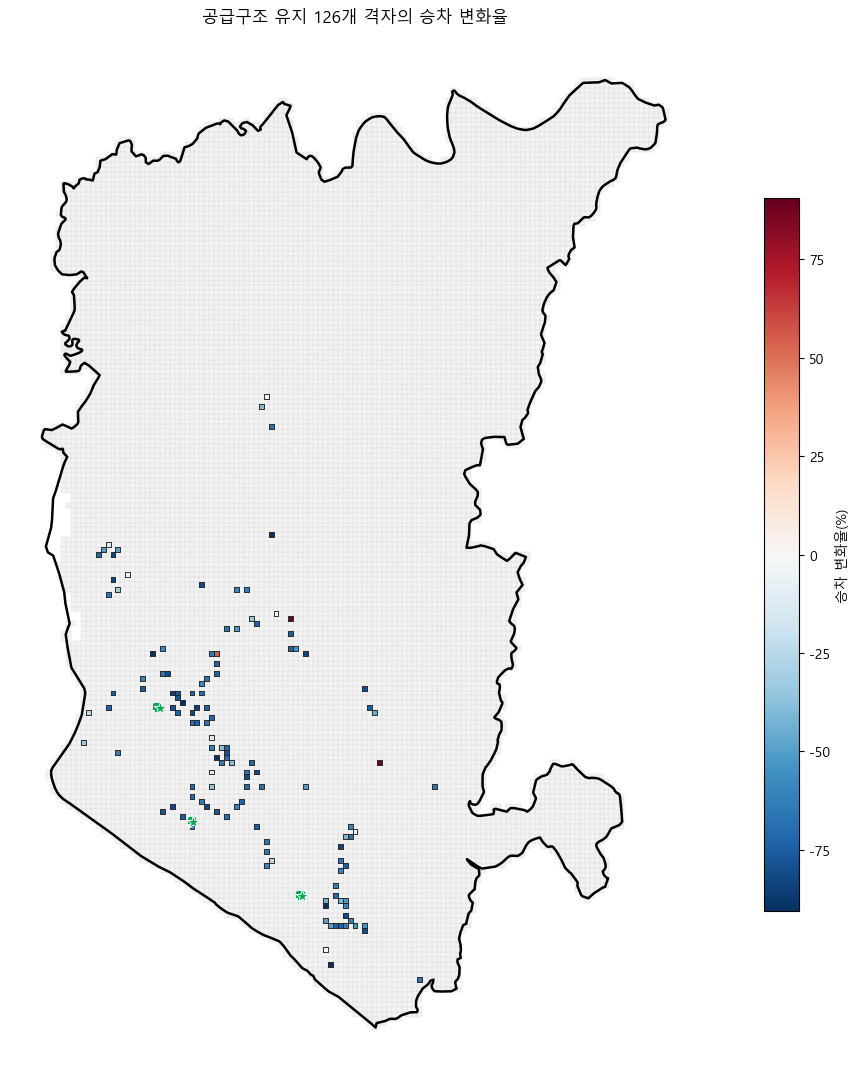

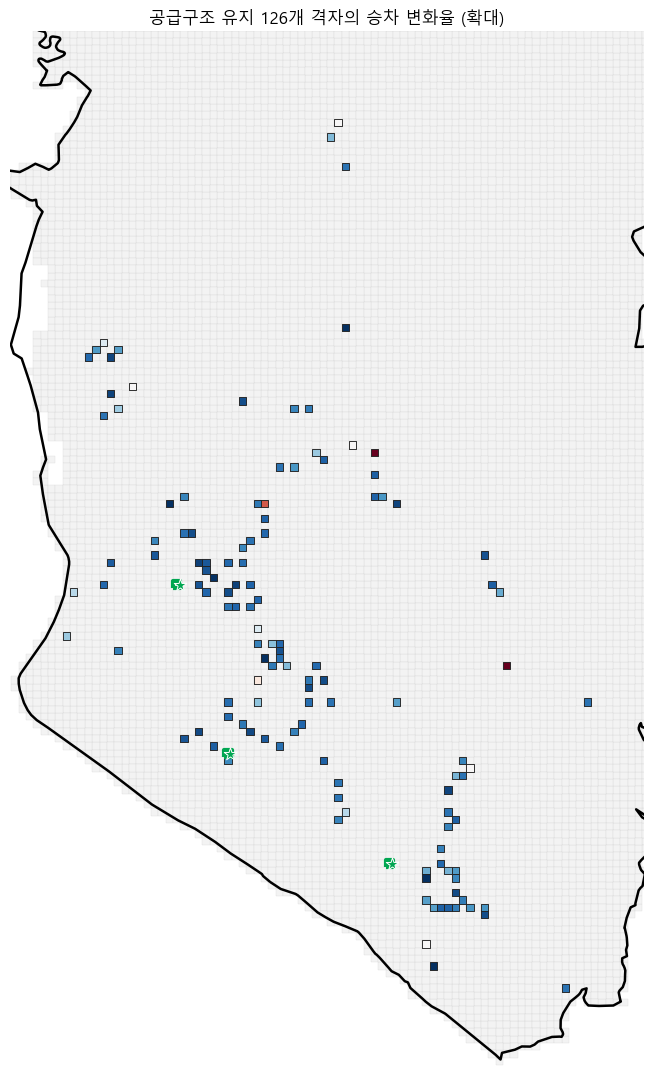

In [2]:
limit = max(1, float(plot_grid['변화율(%)'].abs().quantile(0.95)))
norm = TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)

def draw_map(ax, zoom=False, legend=True):
    grid.plot(ax=ax, facecolor='#F3F3F3', edgecolor='#CFCFCF', linewidth=0.18, zorder=1)
    plot_grid.plot(ax=ax, column='변화율(%)', cmap='RdBu_r', norm=norm, edgecolor='#222222', linewidth=0.65, legend=legend, legend_kwds={'label': '승차 변화율(%)', 'shrink': 0.68}, zorder=2)
    station_cells.boundary.plot(ax=ax, color='#00A651', linewidth=3.0, zorder=4)
    stations.plot(ax=ax, color='#00A651', marker='*', markersize=90, edgecolor='white', linewidth=0.7, zorder=5)
    boundary_gdf.boundary.plot(ax=ax, color='black', linewidth=1.8, zorder=6)
    if zoom:
        xmin, ymin, xmax, ymax = plot_grid.total_bounds
        padx, pady = (xmax-xmin)*0.10, (ymax-ymin)*0.10
        ax.set_xlim(xmin-padx, xmax+padx); ax.set_ylim(ymin-pady, ymax+pady)
    ax.set_title('공급구조 유지 126개 격자의 승차 변화율' + (' (확대)' if zoom else ''))
    ax.set_axis_off()

fig, ax = plt.subplots(figsize=(13, 11)); draw_map(ax, zoom=False, legend=True); plt.tight_layout()
fig.savefig(FIGURES / '01_전체_격자별_승차변화율.png', dpi=220, bbox_inches='tight'); plt.show()
fig, ax = plt.subplots(figsize=(13, 11)); draw_map(ax, zoom=True, legend=False); plt.tight_layout()
fig.savefig(FIGURES / '02_확대_격자별_승차변화율.png', dpi=220, bbox_inches='tight'); plt.show()

## 2. 2024년에서 2025년으로의 승차 변화 애니메이션녹색 테두리는 GTX-A역이 포함된 격자이다.

저장: C:\Users\금경훈\Desktop\Gachon\3-2\UROP\github_2026-UROP\gtx_a_bus_analysis\outputs\figures_011\03_확대_2024_2025_승차변화.gif


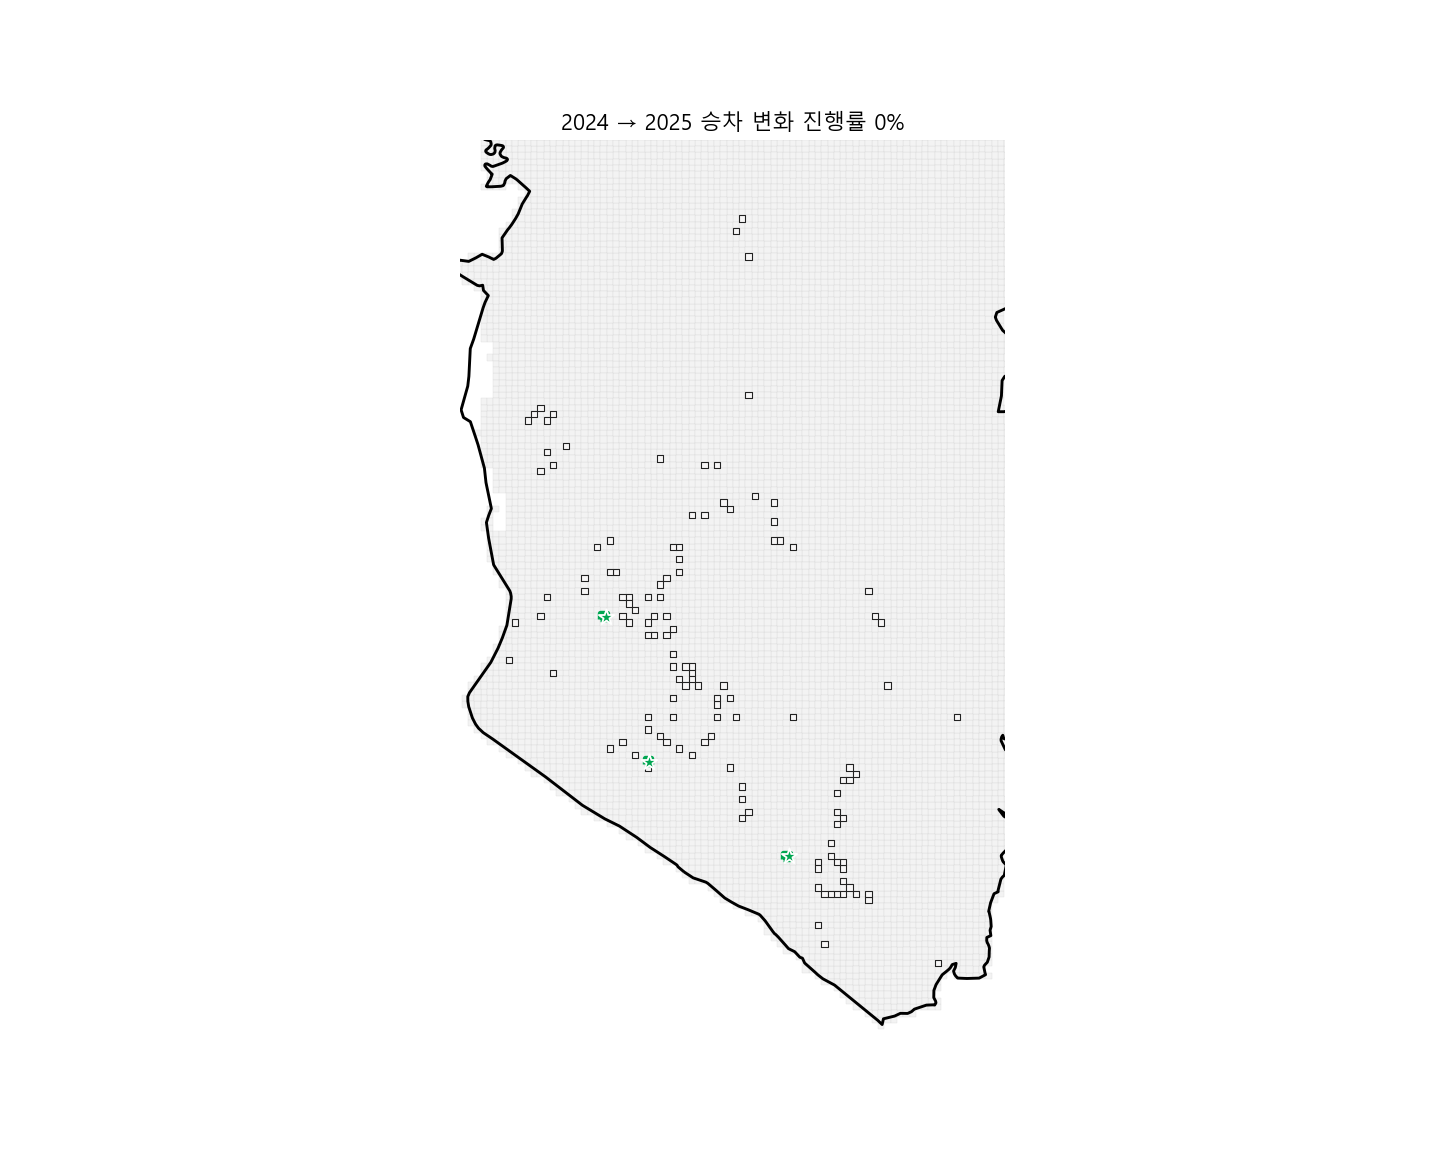

In [3]:
gif_path = FIGURES / '03_확대_2024_2025_승차변화.gif'
fig, ax = plt.subplots(figsize=(11, 9))
frames = np.linspace(0, 1, 25)
def update(progress):
    ax.clear()
    grid.plot(ax=ax, facecolor='#F3F3F3', edgecolor='#D3D3D3', linewidth=0.15, zorder=1)
    animated = plot_grid.copy(); animated['진행 변화율(%)'] = animated['변화율(%)'] * progress
    animated.plot(ax=ax, column='진행 변화율(%)', cmap='RdBu_r', norm=norm, edgecolor='#222222', linewidth=0.6, zorder=2)
    station_cells.boundary.plot(ax=ax, color='#00A651', linewidth=3.0, zorder=4)
    stations.plot(ax=ax, color='#00A651', marker='*', markersize=80, edgecolor='white', zorder=5)
    boundary_gdf.boundary.plot(ax=ax, color='black', linewidth=1.6, zorder=6)
    xmin, ymin, xmax, ymax = plot_grid.total_bounds; padx, pady = (xmax-xmin)*0.10, (ymax-ymin)*0.10
    ax.set_xlim(xmin-padx, xmax+padx); ax.set_ylim(ymin-pady, ymax+pady)
    ax.set_title(f'2024 → 2025 승차 변화 진행률 {progress*100:.0f}%')
    ax.set_axis_off()
anim = FuncAnimation(fig, update, frames=frames, interval=140, repeat=True)
anim.save(gif_path, writer=PillowWriter(fps=7), dpi=130)
plt.close(fig)
print('저장:', gif_path)
display(Image(filename=str(gif_path)))

## 3. 250m 격자별 GTX-A역과의 거리구간별 승차인원 변화

최근접 GTX-A역과 격자 중심점 사이의 직선거리를 비누적 구간으로 구분한다. 따라서 각 격자는 하나의 거리구간에만 포함된다.


In [2]:
# 250m 격자별 GTX-A역과의 비누적 거리구간별 승차인원 변화
# 이 셀은 앞 셀 실행 여부와 관계없이 단독으로 실행할 수 있다.
from pathlib import Path
import geopandas as gpd
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_DISTANCE = Path.cwd().parent if Path.cwd().name == 'analysis' else Path.cwd()
PROCESSED_DISTANCE = PROJECT_DISTANCE / 'data' / 'processed'
FIGURES_DISTANCE = PROJECT_DISTANCE / 'outputs' / 'figures_011'
FIGURES_DISTANCE.mkdir(parents=True, exist_ok=True)

MODEL_DISTANCE_PATH = next(PROCESSED_DISTANCE.glob('18_*.csv'))
distance_model = pd.read_csv(MODEL_DISTANCE_PATH, encoding='utf-8-sig')
distance_model['셀 ID'] = pd.to_numeric(distance_model['셀 ID'], errors='coerce').astype('Int64')

# 격자 중심점과 GTX-A 3개 역을 EPSG:5179로 투영한 뒤 km 단위 직선거리를 계산한다.
distance_cells = gpd.GeoDataFrame(
    distance_model.copy(),
    geometry=gpd.points_from_xy(
        distance_model['중심점 경도'], distance_model['중심점 위도']
    ),
    crs='EPSG:4326',
).to_crs('EPSG:5179')

distance_stations = gpd.GeoDataFrame(
    {'GTX-A역': ['운정중앙역', '킨텍스역', '대곡역']},
    geometry=gpd.points_from_xy(
        [126.728330, 126.748060, 126.811024],
        [37.716670, 37.665000, 37.631626],
    ),
    crs='EPSG:4326',
).to_crs('EPSG:5179')

distance_matrix = np.column_stack([
    distance_cells.geometry.distance(station_geometry) / 1000
    for station_geometry in distance_stations.geometry
])
distance_cells['최근접 GTX-A역'] = np.asarray(distance_stations['GTX-A역'])[
    distance_matrix.argmin(axis=1)
]
distance_cells['최근접역 거리(km)'] = distance_matrix.min(axis=1)

# 0~1km부터 4~5km까지는 1km 간격이며, 5km 이상은 하나로 묶는다.
distance_bins = [0, 1, 2, 3, 4, 5, np.inf]
distance_labels = ['0~1km', '1~2km', '2~3km', '3~4km', '4~5km', '5km 이상']
distance_cells['GTX-A역 거리구간'] = pd.cut(
    distance_cells['최근접역 거리(km)'],
    bins=distance_bins,
    labels=distance_labels,
    right=False,
    include_lowest=True,
)
distance_cells['감소 셀 여부'] = distance_cells['change_all'] < 0

distance_table = (
    distance_cells.groupby('GTX-A역 거리구간', observed=False)
    .agg(
        셀_수=('셀 ID', 'size'),
        **{
            '2024년 승차인원': ('board_2024_all', 'sum'),
            '2025년 승차인원': ('board_2025_all', 'sum'),
            '승차인원 변화량': ('change_all', 'sum'),
            '승차인원 변화 중앙값': ('change_all', 'median'),
            '감소 셀': ('감소 셀 여부', 'sum'),
        },
    )
    .reset_index()
    .rename(columns={'셀_수': '셀 수'})
)
distance_table['승차인원 변화율(%)'] = np.where(
    distance_table['2024년 승차인원'] > 0,
    distance_table['승차인원 변화량'] / distance_table['2024년 승차인원'] * 100,
    np.nan,
)
distance_table['감소 비율(%)'] = np.where(
    distance_table['셀 수'] > 0,
    distance_table['감소 셀'] / distance_table['셀 수'] * 100,
    np.nan,
)

distance_table = distance_table[[
    'GTX-A역 거리구간', '셀 수', '승차인원 변화 중앙값',
    '감소 셀', '감소 비율(%)'
]]

total_row = pd.DataFrame([{
    'GTX-A역 거리구간': '전체',
    '셀 수': len(distance_cells),
    '승차인원 변화 중앙값': distance_cells['change_all'].median(),
    '감소 셀': int(distance_cells['감소 셀 여부'].sum()),
    '감소 비율(%)': distance_cells['감소 셀 여부'].mean() * 100,
}])
distance_table_with_total = pd.concat([distance_table, total_row], ignore_index=True)

print('[250m 격자별 GTX-A역과의 거리구간별 승차인원 변화]')
display(distance_table_with_total.round(1))

distance_output = FIGURES_DISTANCE / '04_GTX-A역_거리구간별_승차인원변화_요약.csv'
distance_table_with_total.to_csv(distance_output, index=False, encoding='utf-8-sig')
print('저장:', distance_output)


 격자별 GTX-A역과의 거리구간별 승차인원 변화]


,GTX-A역 거리구간,셀 수,승차인원 변화 중앙값,감소 셀,감소 비율(%)
0,0~1km,4,-495.5,4,100.0
1,1~2km,26,-76.5,26,100.0
2,2~3km,29,-54.0,27,93.1
3,3~4km,28,-34.5,28,100.0
4,4~5km,6,-11.5,4,66.7
5,5km 이상,33,-8.0,28,84.8
6,전체,126,-39.5,117,92.9


저장: c:\Users\금경훈\Desktop\Gachon\3-2\UROP\github_2026-UROP\gtx_a_bus_analysis\outputs\figures_011\04_GTX-A역_거리구간별_승차인원변화_요약.csv


## 4. 전체 감소·유지·증가 셀 수

,구분,셀 수,비율(%)
0,감소,117,92.9
1,유지,5,4.0
2,증가,4,3.2


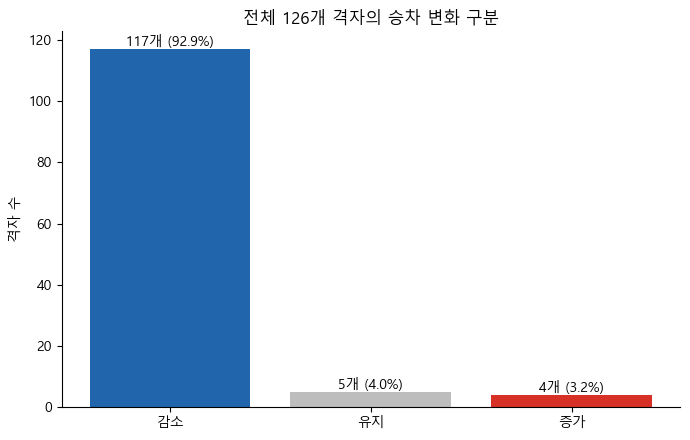

In [5]:
model['변화 구분'] = np.select([model['change_all'] < 0, model['change_all'] > 0], ['감소', '증가'], default='유지')
change_summary = model['변화 구분'].value_counts().reindex(['감소','유지','증가'], fill_value=0).rename_axis('구분').reset_index(name='셀 수')
change_summary['비율(%)'] = change_summary['셀 수'] / len(model) * 100
display(change_summary.round(1))
fig, ax = plt.subplots(figsize=(7, 4.5))
colors = {'감소':'#2166ac','유지':'#bdbdbd','증가':'#d73027'}
bars = ax.bar(change_summary['구분'], change_summary['셀 수'], color=[colors[x] for x in change_summary['구분']])
for bar, n, pct in zip(bars, change_summary['셀 수'], change_summary['비율(%)']): ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1, f'{n}개 ({pct:.1f}%)', ha='center')
ax.set_ylabel('격자 수'); ax.set_title('전체 126개 격자의 승차 변화 구분'); ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); fig.savefig(FIGURES / '05_감소_유지_증가_셀수.png', dpi=220, bbox_inches='tight'); plt.show()

## 5. 노선별 승차 변화율

공급구조가 유지된 126개 셀에 포함된 승차기록만 노선별로 합산한다. 노선 수가 많으므로 변화율 순서대로 절반씩 나누어 두 개의 그림으로 제시한다.


,노선,2024년 승차인원,2025년 승차인원,증감,변화율(%)
0,3400,879,175,-704,-80.1
1,M7154,369,75,-294,-79.7
2,9030-1,39,9,-30,-76.9
3,7101,554,137,-417,-75.3
4,G7625,622,156,-466,-74.9
5,1500,1189,309,-880,-74.0
6,3100,900,240,-660,-73.3
7,1000,3547,948,-2599,-73.3
8,9600,118,32,-86,-72.9
9,9710,220,60,-160,-72.7


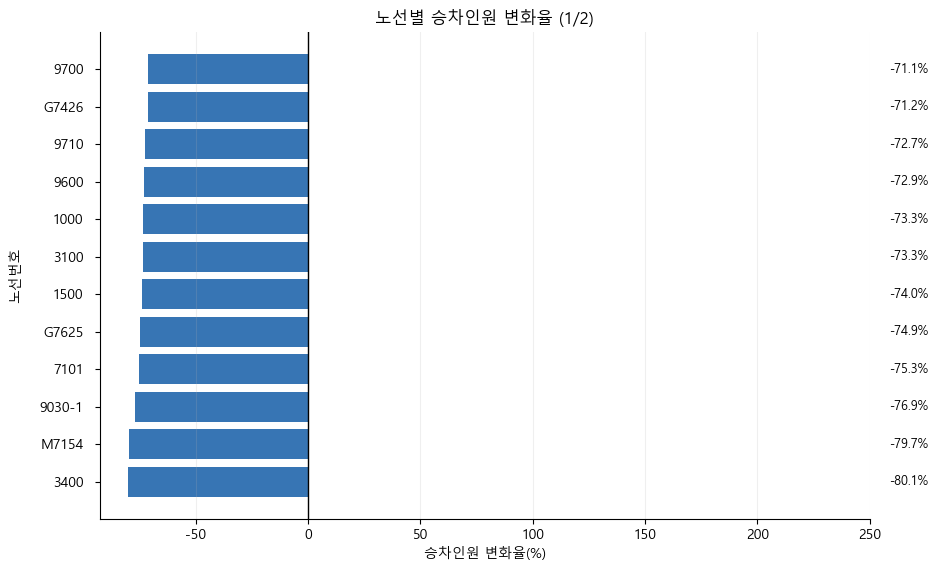

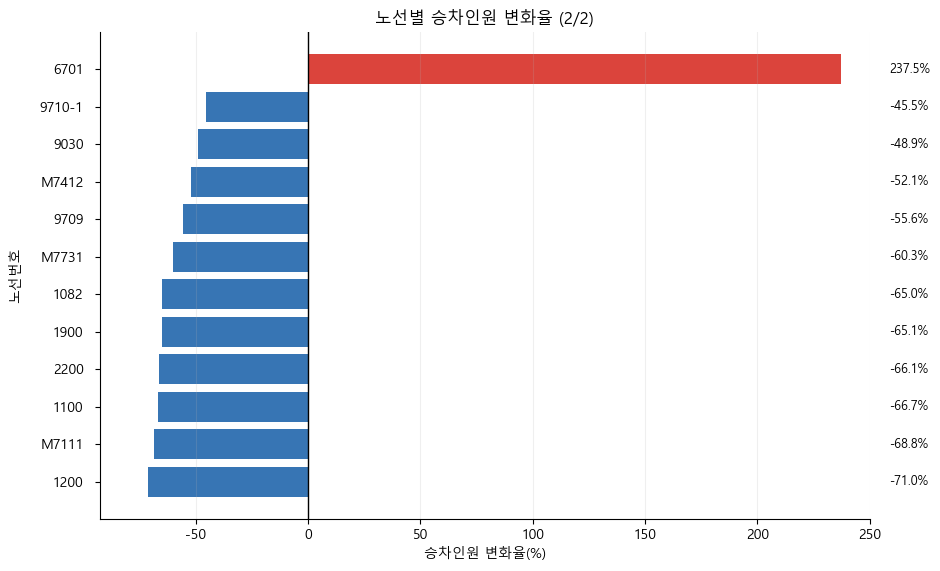

In [6]:
# 노선별 승차 변화율: 노선을 절반씩 나누어 두 개의 그림으로 출력
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from IPython.display import display

PROJECT_ROUTE = Path.cwd().parent if Path.cwd().name == 'analysis' else Path.cwd()
ROOT_ROUTE = PROJECT_ROUTE.parents[1]
PROCESSED_ROUTE = PROJECT_ROUTE / 'data' / 'processed'
FIGURES_ROUTE = PROJECT_ROUTE / 'outputs' / 'figures_011'
FIGURES_ROUTE.mkdir(parents=True, exist_ok=True)

STABLE_ROUTE_PATH = next(PROCESSED_ROUTE.glob('16_*.csv'))
CARD_DIR_ROUTE = ROOT_ROUTE / 'gtx_a_seoul_bus_outputs' / 'transport_card'
RAW24_ROUTE = CARD_DIR_ROUTE / 'gtx_a_transport_card_20241017_raw_with_coords_api_filled.csv'
RAW25_ROUTE = CARD_DIR_ROUTE / 'gtx_a_transport_card_20251106_raw_with_coords.csv'

font_path_route = Path(r'C:\Windows\Fonts\malgun.ttf')
if font_path_route.exists():
    fm.fontManager.addfont(str(font_path_route))
    plt.rcParams['font.family'] = fm.FontProperties(fname=str(font_path_route)).get_name()
plt.rcParams['axes.unicode_minus'] = False

stable_route = pd.read_csv(STABLE_ROUTE_PATH, encoding='utf-8-sig')
stable_route['셀 ID'] = pd.to_numeric(stable_route['셀 ID'], errors='coerce').astype('Int64')

def split_stop_ids(value):
    return [
        item.strip() for item in str(value).split('|')
        if item.strip() and item.strip().lower() != 'nan'
    ]

stop_to_cell = {}
for year, column in [(2024, '2024년 정류장 ID'), (2025, '2025년 정류장 ID')]:
    stop_to_cell[year] = {
        stop_id: int(row['셀 ID'])
        for _, row in stable_route.iterrows()
        for stop_id in split_stop_ids(row[column])
    }

def aggregate_route_boarding(raw_path, year):
    data = pd.read_csv(raw_path, encoding='utf-8-sig', low_memory=False)
    stop_id = data['ride_sttn_id'].astype(str).str.replace(r'\.0$', '', regex=True)
    data['셀 ID'] = stop_id.map(stop_to_cell[year])
    data['승차인원'] = pd.to_numeric(data['utztn_nope'], errors='coerce').fillna(0)
    data['노선'] = data['query_route_no'].astype(str).str.replace(r'\.0$', '', regex=True)
    return data[data['셀 ID'].notna()].groupby('노선')['승차인원'].sum()

route_2024 = aggregate_route_boarding(RAW24_ROUTE, 2024)
route_2025 = aggregate_route_boarding(RAW25_ROUTE, 2025)
route_change = pd.concat([
    route_2024.rename('2024년 승차인원'),
    route_2025.rename('2025년 승차인원'),
], axis=1).fillna(0).reset_index()
route_change['증감'] = route_change['2025년 승차인원'] - route_change['2024년 승차인원']
route_change['변화율(%)'] = np.where(
    route_change['2024년 승차인원'] > 0,
    route_change['증감'] / route_change['2024년 승차인원'] * 100,
    np.nan,
)
route_change = route_change.sort_values('변화율(%)').reset_index(drop=True)
display(route_change.round(1))
# 두 그림 모두 전체 노선의 최솟값·최댓값을 이용한 동일한 x축 범위를 사용한다.
finite_rate = route_change['변화율(%)'].replace([np.inf, -np.inf], np.nan).dropna()
x_padding = max(5.0, float(finite_rate.max() - finite_rate.min()) * 0.04)
shared_x_min = float(finite_rate.min()) - x_padding
shared_x_max = float(finite_rate.max()) + x_padding

midpoint = int(np.ceil(len(route_change) / 2))
route_parts = [route_change.iloc[:midpoint], route_change.iloc[midpoint:]]

for figure_number, route_part in enumerate(route_parts, start=1):
    fig_height = max(5.8, len(route_part) * 0.52)
    fig, ax = plt.subplots(figsize=(11.5, fig_height))
    colors = np.where(route_part['변화율(%)'] < 0, '#2166ac', '#d73027')
    ax.barh(route_part['노선'], route_part['변화율(%)'], color=colors, alpha=0.9)
    ax.axvline(0, color='black', linewidth=1)
    ax.set_xlim(shared_x_min, shared_x_max)
    ax.set_xlabel('승차인원 변화율(%)')
    ax.set_ylabel('노선번호', labelpad=12)
    ax.set_title(f'노선별 승차인원 변화율 ({figure_number}/2)')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='x', alpha=0.2)
    ax.tick_params(axis='y', pad=8, labelsize=10)

    # 변화율 수치는 막대 끝이 아닌 오른쪽 고정 열에 배치하여 노선번호와 겹치지 않게 한다.
    for y_position, value in enumerate(route_part['변화율(%)']):
        if pd.notna(value):
            ax.text(
                1.025, y_position, f'{value:.1f}%',
                transform=ax.get_yaxis_transform(),
                va='center', ha='left', fontsize=9, clip_on=False,
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.78, pad=1.0),
            )

    # 오른쪽 여백은 변화율 숫자만 표시하는 별도 공간이다.
    fig.subplots_adjust(left=0.16, right=0.83, top=0.90, bottom=0.12)
    plt.show()


## 6. 126개 격자의 2024년 건축물 연면적 지도

11-8 OLS 기본모형에서 유의하게 나타난 2024년 건축물 연면적(천㎡)의 공간분포를 공급구조 유지 126개 격자에 표시한다. 색이 진할수록 격자 안의 건축물 연면적이 크다. 연면적 분포가 오른쪽으로 치우쳐 있어 낮은 값의 공간 차이도 보이도록 제곱근 색상 정규화를 적용하였다. 녹색 별과 테두리는 GTX-A역 위치 및 역 포함 격자이다.

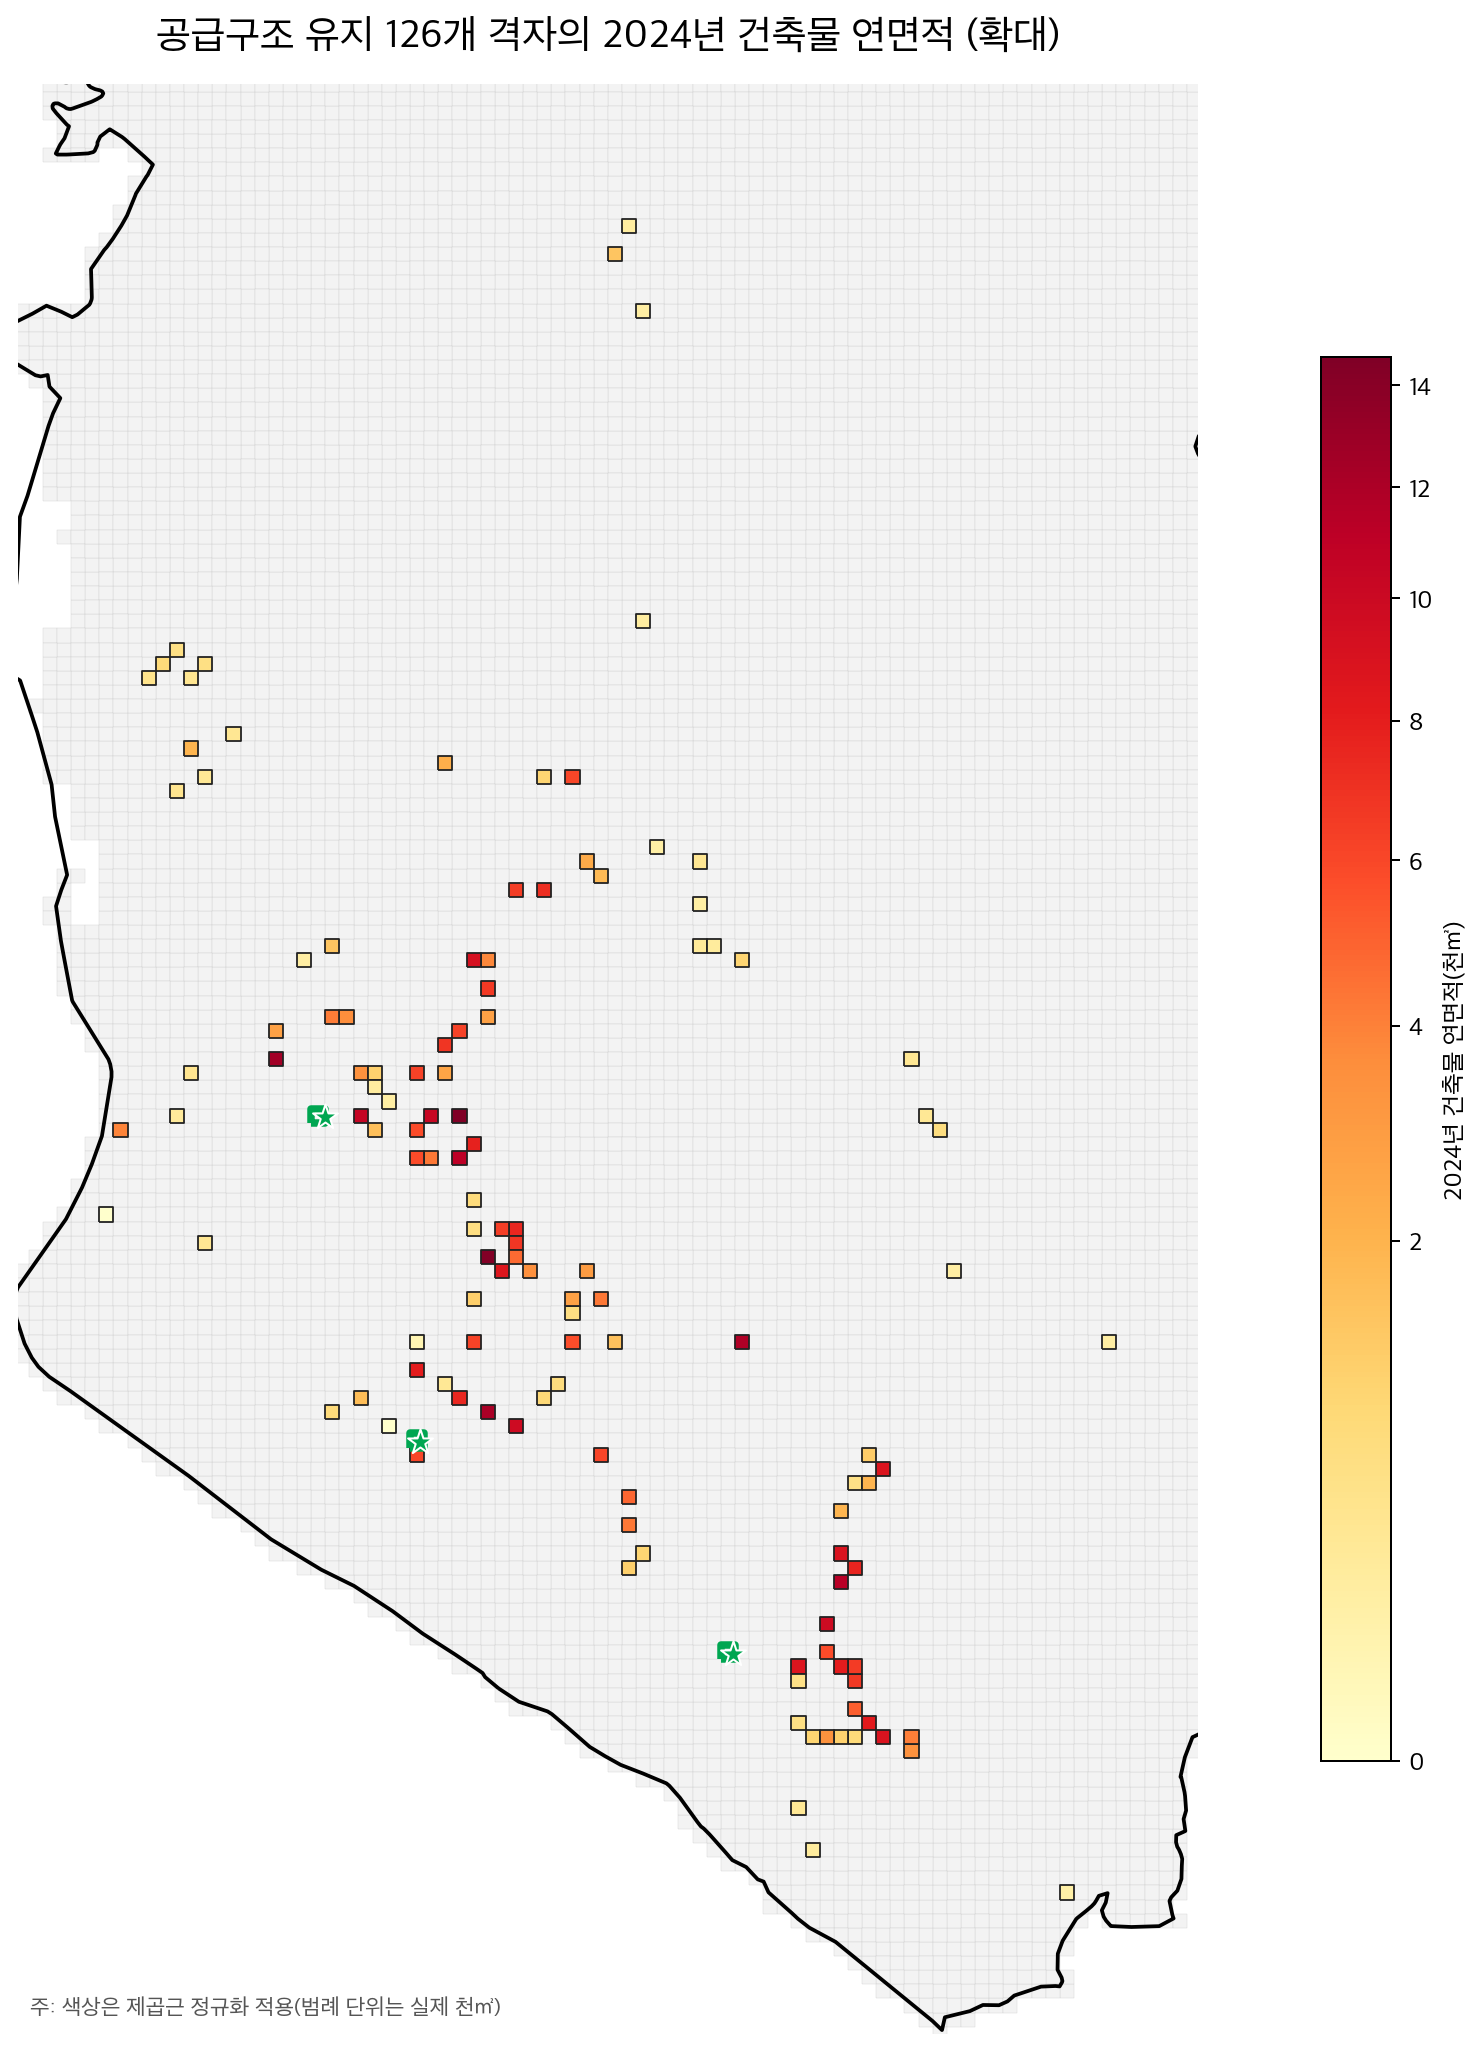

In [7]:
# 126개 분석 격자의 2024년 건축물 연면적 확대 지도
# 앞 셀의 지도 객체를 이용하며, 연면적 자료만 셀 ID로 추가 병합한다.
from matplotlib.colors import PowerNorm

FLOOR_PATH = PROCESSED / '24_건축물연면적_2024_250m격자.csv'
floor = pd.read_csv(FLOOR_PATH, encoding='utf-8-sig')
floor['셀 ID'] = pd.to_numeric(floor['셀 ID'], errors='coerce').astype('Int64')
floor_col = '2024년 건축물 연면적(천㎡)'

floor_grid = plot_grid[['셀 ID', 'geometry']].merge(
    floor[['셀 ID', floor_col]],
    on='셀 ID', how='left', validate='one_to_one'
)
assert len(floor_grid) == 126, f'분석 격자 수 오류: {len(floor_grid)}'
assert floor_grid[floor_col].notna().all(), '건축물 연면적 결측값이 있습니다.'

floor_summary = floor_grid[floor_col].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
).rename('건축물 연면적(천㎡)').to_frame()
display(floor_summary.round(3))

vmax = float(floor_grid[floor_col].max())
floor_norm = PowerNorm(gamma=0.5, vmin=0, vmax=vmax)

fig, ax = plt.subplots(figsize=(14, 11.5))
grid.plot(
    ax=ax, facecolor='#F3F3F3', edgecolor='#D0D0D0',
    linewidth=0.16, zorder=1
)
floor_grid.plot(
    ax=ax, column=floor_col, cmap='YlOrRd', norm=floor_norm,
    edgecolor='#222222', linewidth=0.72, legend=True,
    legend_kwds={'label': '2024년 건축물 연면적(천㎡)', 'shrink': 0.72},
    zorder=2
)
station_cells.boundary.plot(ax=ax, color='#00A651', linewidth=3.0, zorder=4)
stations.plot(
    ax=ax, color='#00A651', marker='*', markersize=110,
    edgecolor='white', linewidth=0.8, zorder=5
)
boundary_gdf.boundary.plot(ax=ax, color='black', linewidth=1.5, zorder=6)

xmin, ymin, xmax, ymax = floor_grid.total_bounds
padx, pady = (xmax-xmin)*0.08, (ymax-ymin)*0.08
ax.set_xlim(xmin-padx, xmax+padx)
ax.set_ylim(ymin-pady, ymax+pady)
ax.set_title('공급구조 유지 126개 격자의 2024년 건축물 연면적 (확대)', fontsize=16, pad=14)
ax.text(
    0.01, 0.01, '주: 색상은 제곱근 정규화 적용(범례 단위는 실제 천㎡)',
    transform=ax.transAxes, fontsize=9, color='#555555'
)
ax.set_axis_off()
plt.tight_layout()

plt.show()


## 7. A3 Ridge Logistic OOF 오차행렬

12-5의 중첩 Leave-One-Station-Out OOF 예측 결과를 전체 및 역 권역별 오차행렬로 표시한다. 분류 기준은 증가확률 0.5이며, 괄호 안 비율은 각 실제 집단 행 안에서의 비율이다.

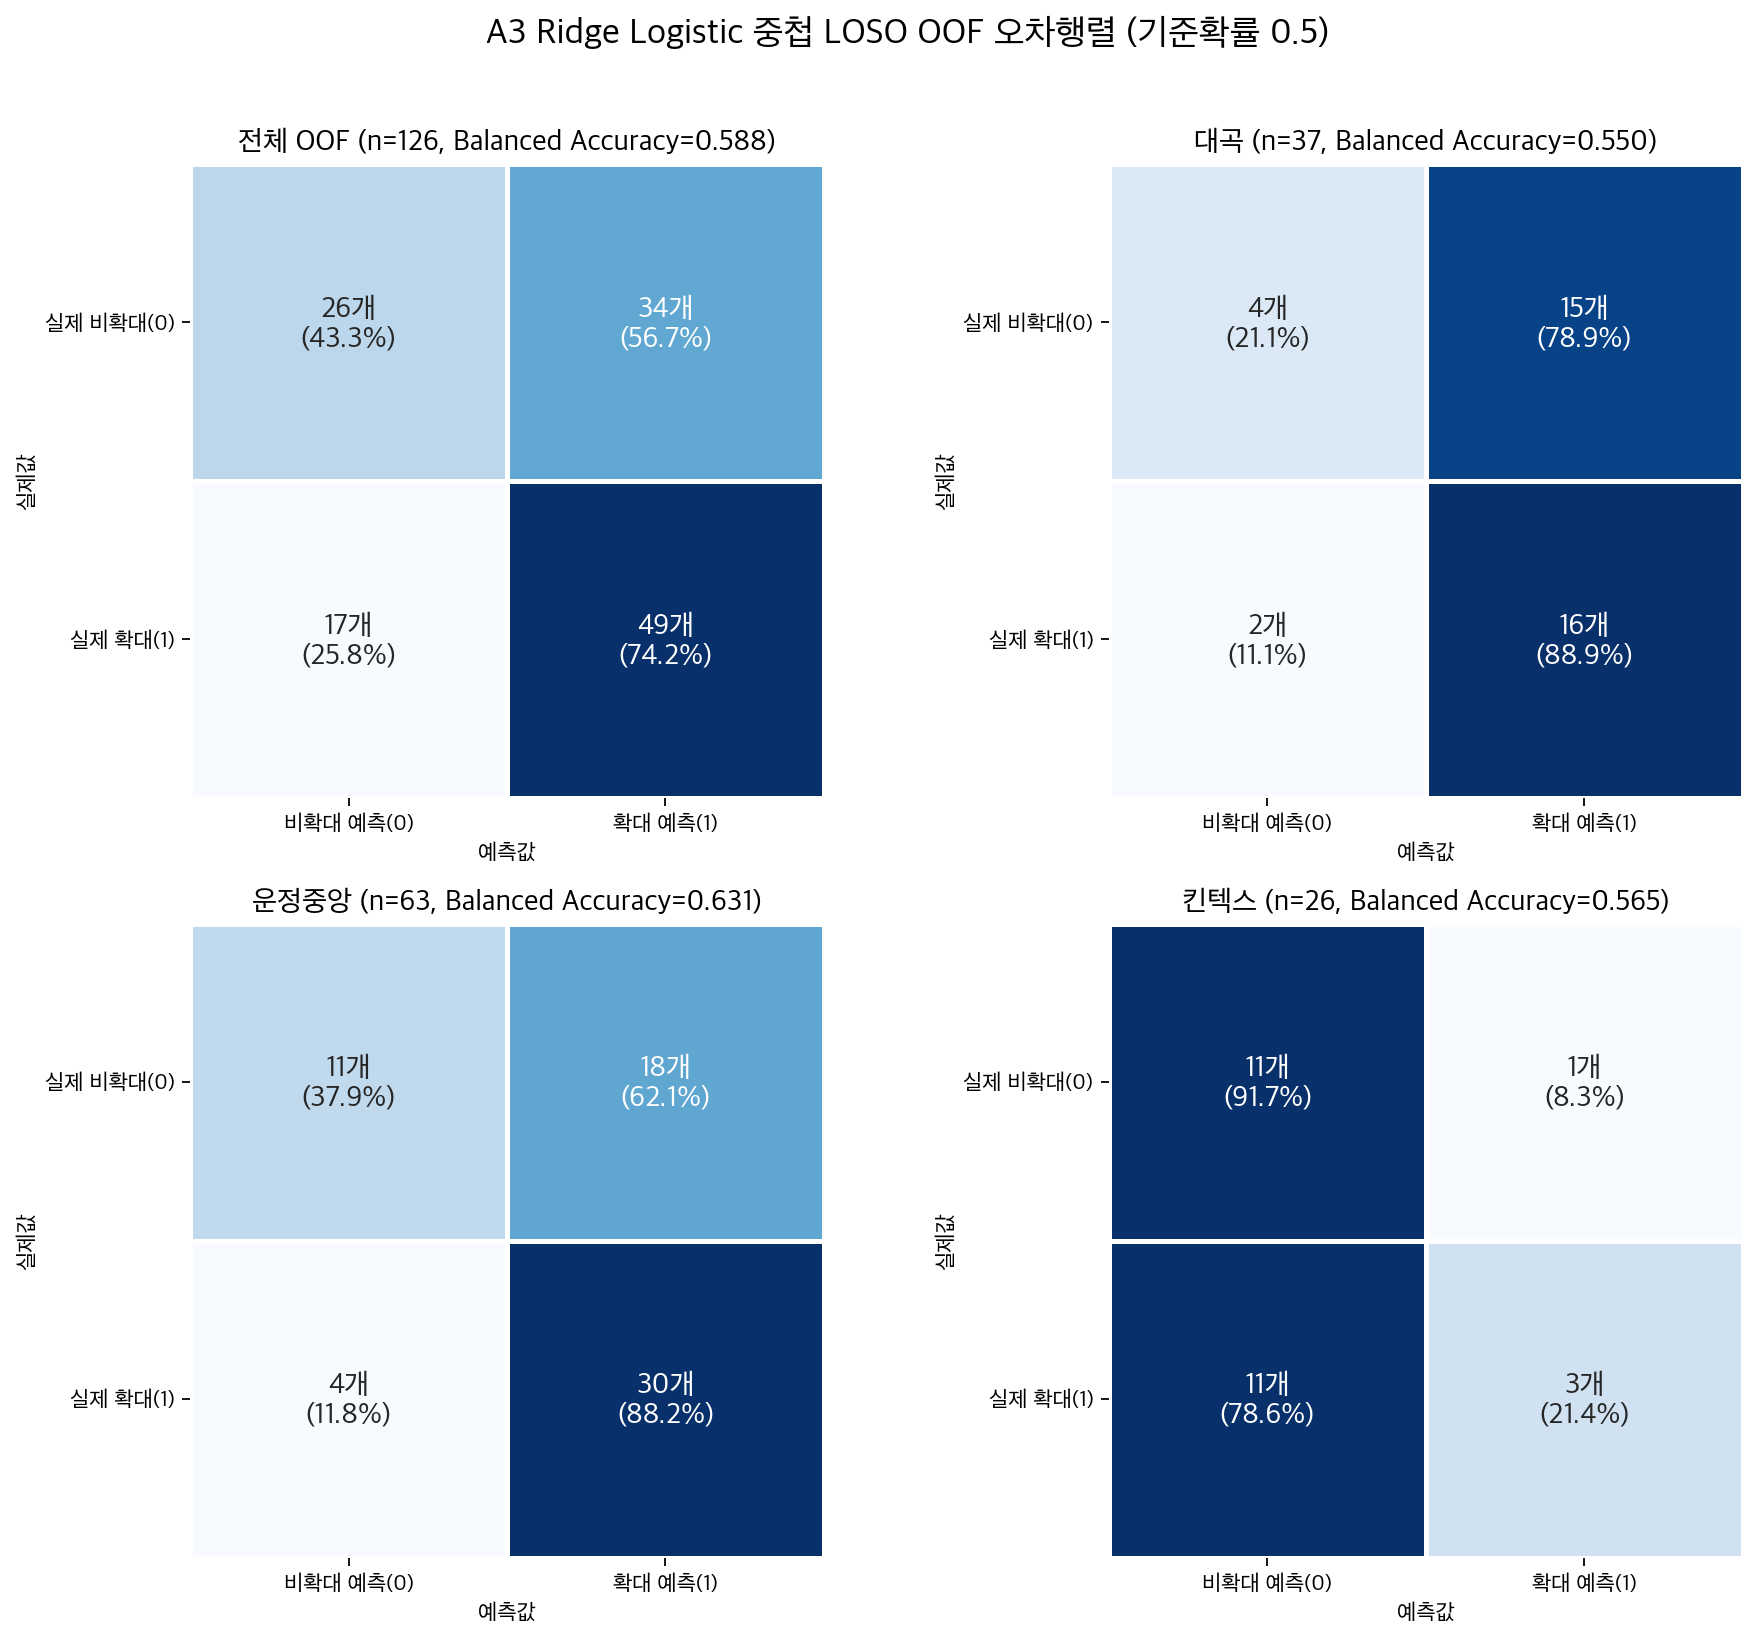

    구분  표본 수  TN  FP  FN  TP  Accuracy  Balanced Accuracy  Sensitivity  Specificity
전체 OOF   126  26  34  17  49     0.595              0.588        0.742        0.433
    대곡    37   4  15   2  16     0.541              0.550        0.889        0.211
  운정중앙    63  11  18   4  30     0.651              0.631        0.882        0.379
   킨텍스    26  11   1  11   3     0.538              0.565        0.214        0.917


In [ ]:
# A3 중첩 LOSO OOF 오차행렬 시각화
# 12-5에서 검증된 OOF 집계값을 사용한다.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

plt.rcParams['font.family'] = 'Apple SD Gothic Neo'
plt.rcParams['axes.unicode_minus'] = False

confusion_results = {
    '전체 OOF': np.array([[26, 34], [17, 49]]),
    '대곡': np.array([[4, 15], [2, 16]]),
    '운정중앙': np.array([[11, 18], [4, 30]]),
    '킨텍스': np.array([[11, 1], [11, 3]]),
}

def annotations(cm):
    row_total = cm.sum(axis=1, keepdims=True)
    row_pct = np.divide(cm, row_total, out=np.zeros_like(cm, dtype=float), where=row_total != 0) * 100
    return np.array([
        [f'{cm[i, j]}개\n({row_pct[i, j]:.1f}%)' for j in range(2)]
        for i in range(2)
    ])

def balanced_accuracy_from_cm(cm):
    specificity = cm[0, 0] / cm[0].sum()
    sensitivity = cm[1, 1] / cm[1].sum()
    return (specificity + sensitivity) / 2

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, cm) in zip(axes.flat, confusion_results.items()):
    sns.heatmap(
        cm, annot=annotations(cm), fmt='', cmap='Blues', cbar=False,
        linewidths=1.5, linecolor='white', square=True, ax=ax,
        xticklabels=['비확대 예측(0)', '확대 예측(1)'],
        yticklabels=['실제 비확대(0)', '실제 확대(1)'],
        annot_kws={'size': 13, 'weight': 'bold'},
    )
    n = int(cm.sum())
    balanced_accuracy = balanced_accuracy_from_cm(cm)
    ax.set_title(
        f'{name} (n={n}, Balanced Accuracy={balanced_accuracy:.3f})',
        fontsize=13, weight='bold'
    )
    ax.set_xlabel('예측값')
    ax.set_ylabel('실제값')
    ax.tick_params(axis='x', rotation=0)
    ax.tick_params(axis='y', rotation=0)

fig.suptitle(
    'A3 Ridge Logistic 중첩 LOSO OOF 오차행렬 (기준확률 0.5)',
    fontsize=16, weight='bold', y=1.02
)
plt.tight_layout()
plt.show()

metric_rows = []
for name, cm in confusion_results.items():
    tn, fp, fn, tp = cm.ravel()
    metric_rows.append({
        '구분': name, '표본 수': cm.sum(),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'Accuracy': (tn + tp) / cm.sum(),
        'Balanced Accuracy': balanced_accuracy_from_cm(cm),
        'Sensitivity': tp / (tp + fn),
        'Specificity': tn / (tn + fp),
    })
metrics = pd.DataFrame(metric_rows)
display(metrics.round(3))

### 해석

- 전체 OOF에서는 실제 확대 격자 66개 중 49개를 확대라고 맞혀 민감도가 높다.
- 실제 비확대 격자 60개 중 26개만 비확대로 맞혀 특이도는 상대적으로 낮다.
- 따라서 현재 모형은 확대 후보를 폭넓게 찾는 성향이 있으며, GTX-B·C에서는 0/1 확정 분류보다 예측점수의 상대적 순위를 중심으로 활용한다.
- ROC-AUC는 임계값 전체에서 순위 판별력을 평가하고, 이 오차행렬은 임계값 0.5에서의 최종 분류 결과를 보여준다.